### Notebook #2: Binary Classification at Four BPM Cutoffs

Classification of NBA player-seasons into "above-threshold" vs. "below-threshold" tiers at four Box Plus-Minus (BPM) cutoffs (Rotation Player, Starter, Star, and Superstar). For each cutoff, we train and tune three classifiers — Logistic Regression, Random Forest, and Gradient Boosting — using 5-fold cross-validation on an 80% training split. We then evaluate the best version of each model on a held-out 20% test set, reporting confusion matrix, ROC curve, AUC, macro F1 score, and accuracy.

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Load clean data
df = pd.read_csv('data/nba_clean.csv')
print(f"Loaded {len(df)} rows × {len(df.columns)} columns\n")
print("Columns:", df.columns.tolist())

Loaded 6020 rows × 42 columns

Columns: ['Player', 'player_id', 'Year', 'Team', 'Age', 'height_in', 'weight_lb', 'experience', 'Pos_primary', 'G', 'GS', 'MP', 'total_minutes', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'bpm', 'bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar', 'Salary', 'salary_tier']


### Build the Feature Matrix:

We now need to seperate the dataset into three groups of columns:

Identifiers - (`Player`, `player_id`, `Year`, `Team`) — preserved for reference but excluded from the feature matrix.
Labels - all BPM tier labels, salary (used later for multi-class), salary tier (used later for multi-class), and position (used laters for clustering). Excluded from features to avoid information leakage from target to predictor.
Features - everything else: per-game box-score statistics, demographics (age, height, weight, experience), volume (games played, total minutes), and player position.

Position is a feature in binary classification and multi-class classification. For clustering, we use it as the ground-truth label used to compute Rand Index. Therefore, we need it in both Features and Labels, and it will removed from the features dataset when we do our position clustering.

In [8]:
identifier_cols = ['Player', 'player_id', 'Year', 'Team']
label_cols = [
    'bpm', 'bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar',
    'Salary', 'salary_tier',
]

# Our numerical features are anything not in position, identifier and label columns
numerical_features = []
excluded = identifier_cols + label_cols + ['Pos_primary']
for c in df.columns:
    if c not in excluded:
        numerical_features.append(c)


# We need to convert the strings of "PG" , "SG" , "SF" , "PF" , "C" into ints that python can handle.
# What we do is create one binary column per position (1 if player is that position, 0 if not).
# We also drop one category (position = center), as the columns are linearly dependent (if we know that player is not pg, sg, sf, pf, we know player is a center)
# This avoids multicollinearity
pos_dummies = pd.get_dummies(df['Pos_primary'], prefix='pos', drop_first=True).astype(int)

# numerical_features is now 30 numerical columns, pos_dummies is a DataFrame of 4 binary position indicators (1 if that position, 0 if not)

#This line puts them together into the final feature matrix
X = pd.concat([df[numerical_features], pos_dummies], axis=1)

# Now need to fill NaN shooting percentages with 0
# (a player with 0 attempts has undefined percentage; 0 is a sensible feature value
#  since the corresponding attempts column captures the "didn't shoot" signal)
X = X.fillna(0)

print(f"NaNs after fill: {X.isna().sum().sum()}")

print(f"X shape: {X.shape}")
print(f"\nFeature columns ({len(X.columns)}):")
print(X.columns.tolist())

NaNs after fill: 0
X shape: (6020, 34)

Feature columns (34):
['Age', 'height_in', 'weight_lb', 'experience', 'G', 'GS', 'MP', 'total_minutes', 'FG', 'FGA', 'FG%', '3P', '3PA', '3P%', '2P', '2PA', '2P%', 'eFG%', 'FT', 'FTA', 'FT%', 'ORB', 'DRB', 'TRB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PTS', 'pos_PF', 'pos_PG', 'pos_SF', 'pos_SG']


Now we need to split the data into 80% training and 20% test data.

We use the same split across all classifiers and all four BPM cutoffs to ensure results are directly comparable. The split is stratified on `bpm_superstar` — the rarest label (~2% positive rate) - to guarantee both classes are represented proportionally in both partitions. A fixed random seed (`random_state=42`) makes the split fully reproducible.

In [10]:
from sklearn.model_selection import train_test_split

y_all = df[['bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar',
            'salary_tier', 'Pos_primary']]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_all,
    test_size=0.20,
    random_state=42,
    stratify=df['bpm_superstar']
)

print(f"Train: {len(X_train):4d} samples")
print(f"Test:  {len(X_test):4d} samples")
print(f"\nClass balance preserved:")
for label in ['bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar']:
    print(f"  {label:15s} train: {y_train[label].mean():.1%}  test: {y_test[label].mean():.1%}")

Train: 4816 samples
Test:  1204 samples

Class balance preserved:
  bpm_rotation    train: 69.9%  test: 68.8%
  bpm_starter     train: 15.0%  test: 15.8%
  bpm_star        train: 5.3%  test: 5.7%
  bpm_superstar   train: 2.1%  test: 2.2%


### Feature Standardization

Logistic Regression and Support Vector Machines are sensitive to feature scale, since their loss functions weight features proportionally to their magnitudes (a feature ranging 0–40 like PTS would dominate one ranging 0.3–0.6 like FG%). We standardize all features to zero mean and unit variance using `StandardScaler`.

To prevent test-set leakage, the scaler is fit only on the training data, then the same transformation is applied to the test set. Tree-based methods (Random Forest, Gradient Boosting) are scale-invariant, so we'll use the unscaled feature matrix when training those later.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled shape:  {X_test_scaled.shape}")
print(f"\nFeature means after scaling (should be ~0):")
print(X_train_scaled.mean(axis=0)[:5].round(4))
print(f"Feature stds after scaling (should be ~1):")
print(X_train_scaled.std(axis=0)[:5].round(4))

X_train_scaled shape: (4816, 34)
X_test_scaled shape:  (1204, 34)

Feature means after scaling (should be ~0):
[ 0.  0. -0. -0. -0.]
Feature stds after scaling (should be ~1):
[1. 1. 1. 1. 1.]


### Train the First Classifier - Logistic Regression on the Rotation Cutoff

We begin with the simplest classifier (Logistic Regression) on the most balanced cutoff (Rotation Player, ~70/30 split) to validate the full training and evaluation pipeline before scaling to all twelve model-cutoff combinations.

Training Procedure: 

We do not use a fixed 3-way train/validation/test split. Instead, we use 5-fold cross-validation on the training partition to tune hyperparameters, which is more statistically robust on a dataset of this size:

1. The 80% training partition is split internally into 5 equal folds.
2. For each candidate value of the hyperparameter `C`, the model is trained 5 times — each time using 4 folds for training and the remaining fold for validation — and the 5 resulting macro F1 scores are averaged.
3. The `C` value with the highest mean cross-validation macro F1 is selected as the best hyperparameter.
4. A final model is refit using that best `C` on the **entire** training partition (all 4,816 samples), giving the model the maximum amount of training data before final evaluation.
5. The held-out 20% test partition is then used exactly once, in Step 6, to produce the final reported metrics. The test set is never seen during training or hyperparameter selection, ensuring the reported metrics are an unbiased estimate of generalization performance.

Class imbalance handling: Since the Rotation cutoff has a ~70/30 positive/negative split, we set `class_weight='balanced'`, which automatically reweights the loss function to give equal importance to both classes.

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
import pandas as pd


target = 'bpm_rotation' #sets out cutoff
y_train_target = y_train[target] #pulls out target column
y_test_target = y_test[target] #pulls out target column

param_grid = {'C': [0.001, 0.01, 0.1, 1, 10, 100]} #trying different values for hyperparameter C

lr = LogisticRegression(
    # 'balanced' reweights the loss function inversely to class frequency. This way, the model can't achieve 70% accuracy by just predicting 'rotation' for every player
    class_weight='balanced', 
    max_iter=2000,
    random_state=42,
)

grid = GridSearchCV(
    estimator=lr, #which model to tune to
    param_grid=param_grid, #what hyperparameters to try
    cv=5, #5-fold cross-validation
    scoring='f1_macro', #macro F1 averages F1 across both classes equally
    n_jobs=-1, #use CPU in parallel
)

grid.fit(X_train_scaled, y_train_target) # use normalized X training data

# Extract per-hyperparameter CV results from the grid search
cv_results = pd.DataFrame(grid.cv_results_)

# Select the columns that matter here
results_summary = cv_results[[
    'param_C',
    'mean_test_score',
    'std_test_score',
    'rank_test_score',
]].rename(columns={
    'param_C': 'C',
    'mean_test_score': 'Mean_CV_Macro_F1',
    'std_test_score': 'Std',
    'rank_test_score': 'Rank',
}).sort_values('C')

print("5-fold CV results across hyperparameter grid:")
print(results_summary.to_string(index=False) + "\n")

print(f"Best C:           {grid.best_params_['C']}") #extract best C
print(f"Best CV macro F1: {grid.best_score_:.4f}") #extract best macro f1

best_lr = grid.best_estimator_

5-fold CV results across hyperparameter grid:
      C  Mean_CV_Macro_F1      Std  Rank
  0.001          0.767991 0.008805     6
  0.010          0.811852 0.008190     5
  0.100          0.836789 0.004174     4
  1.000          0.838324 0.005836     3
 10.000          0.842579 0.006519     1
100.000          0.840301 0.006763     2

Best C:           10
Best CV macro F1: 0.8426


We've now tuned our hyperparameters using cross-fold validation, we can now evaluate the model using our test data. This test data has not been touched during training or tuning.

We compute these 4 metrics:
Confusion matrix - raw counts of true/false positives and negatives.
ROC curve and AUC - model's ability to separate the two classes across all decision thresholds. AUC of 1.0 is perfect; 0.5 is random.
Macro F1 score - harmonic mean of precision and recall, averaged across both classes (gives equal weight to the minority class).
Accuracy - overall fraction of correct predictions.

=== Logistic Regression — Rotation Cutoff ===
Accuracy:  0.8447
Macro F1:  0.8270
AUC:       0.9342

Confusion Matrix:
[[316  60]
 [127 701]]


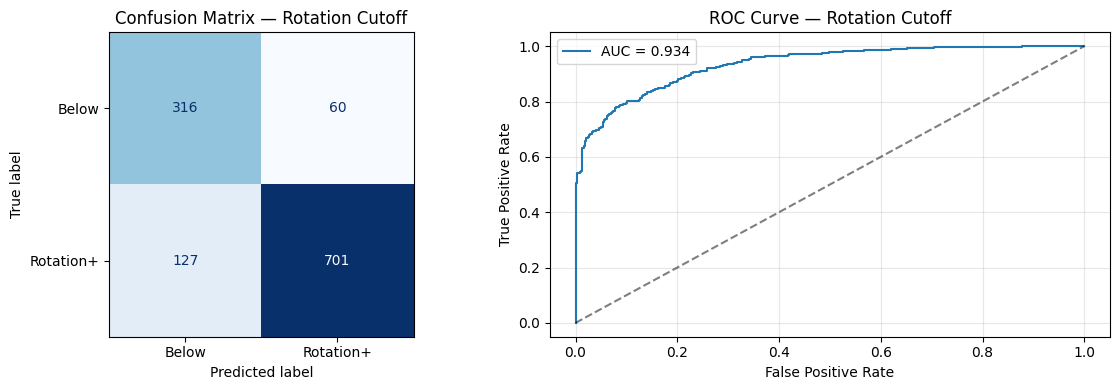

In [16]:
from sklearn.metrics import (
    confusion_matrix, roc_curve, roc_auc_score, f1_score, accuracy_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = best_lr.predict(X_test_scaled)
y_proba = best_lr.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test_target, y_pred)
auc = roc_auc_score(y_test_target, y_proba)
f1_macro = f1_score(y_test_target, y_pred, average='macro')
accuracy = accuracy_score(y_test_target, y_pred)

print(f"=== Logistic Regression — Rotation Cutoff ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Macro F1:  {f1_macro:.4f}")
print(f"AUC:       {auc:.4f}")
print(f"\nConfusion Matrix:")
print(cm)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Below', 'Rotation+'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Confusion Matrix — Rotation Cutoff')

fpr, tpr, _ = roc_curve(y_test_target, y_proba)
axes[1].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Rotation Cutoff')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Results:

The logistic regression model trained on the rotation cutoff achieved 84.5% accuracy, a macro F1 score of 0.827, and an AUC of 0.934 on the held-out test set. The confusion matrix shows the model correctly identified 701 of 828 true Rotation-tier players (recall = 84.7%) and 316 of 376 below-rotation players (recall = 84.0%), with the two error types nearly balanced--60 false positives versus 127 false negatives. The ROC curve climbs steeply from the origin, reaching a true-positive rate above 0.80 at a false-positive rate below 0.10, indicating strong class separability. The AUC of 0.934 means that if we randomly draw one rotation-tier player and one below-rotation player from the test set, the model assigns the rotation-tier player a higher predicted probability 93.4% of the time. These results validate that the full pipeline--feature engineering, train/test split, standardization, 5-fold cross-validated hyperparameter tuning, and held-out evaluation--produces well-calibrated, generalizable predictions, and the pipeline is ready to be scaled to the remaining classifier-cutoff combinations.

### Implications:

In basketball terms, the model has learned to distinguish a meaningful NBA contributor (BPM ≥ −2.0) from a sub-replacement-level player using only that season's box-score statistics, demographics, and listed position--without ever seeing the underlying BPM value itself. The strong performance suggests that the surface-level statistics traditionally used to evaluate players (points, rebounds, assists, efficiency, minutes played) collectively encode most of the information advanced metrics like BPM are designed to capture, at least at the Rotation cutoff. The slight asymmetry in the errors--more false negatives (127) than false positives (60)--indicates the model is somewhat conservative: it is more likely to mislabel a genuinely productive player as below-rotation than to overrate a marginal one. The next step — running the same pipeline at the stricter Starter, Star, and Superstar cutoffs — will test whether this signal-strong relationship between box-score stats and player tier holds up as the threshold for "impactful" rises and the positive class shrinks toward the league's elite.


### Hyperparameter Tuning Strategy for Each Classifier

Before scaling to all twelve classifier-cutoff combinations, we describe the
hyperparameter grid used for each of the three classifiers. All three are
tuned via the same 5-fold cross-validation procedure described in Section 5;
only the hyperparameters themselves differ.

**Logistic Regression** tunes a single hyperparameter, `C` (inverse
regularization strength), swept across six orders of magnitude
(`{0.001, 0.01, 0.1, 1, 10, 100}`). Small values produce strong
regularization that shrinks coefficients toward zero; large values allow
coefficients to grow freely. The optimal value balances fitting the training
data against generalizing to new samples.

**Random Forest** tunes two hyperparameters jointly:

- `n_estimators` (number of trees in the forest), tested at 200 and 500.
  More trees produce more stable predictions through ensemble averaging,
  with diminishing returns beyond a few hundred trees.
- `max_depth` (maximum tree depth), tested at unlimited (`None`), 10, and 20.
  Deeper trees can capture more complex patterns but risk overfitting; shallower
  trees are simpler and generalize better.

The grid contains 2 × 3 = 6 combinations.

**Gradient Boosting** (HistGradientBoostingClassifier) also tunes two
hyperparameters:

- `learning_rate`, tested at 0.05 and 0.1. Recall that gradient boosting builds
  trees sequentially, with each tree correcting the residual errors of the
  previous ones. A smaller learning rate makes each correction more
  conservative, generally improving accuracy and reducing overfitting at the
  cost of slower convergence.
- `max_depth`, tested at unlimited (`None`), 5, and 10. Boosted trees can
  often tolerate greater depth than Random Forest trees because the sequential
  error-correction structure provides natural regularization.

The grid contains 2 × 3 = 6 combinations.

For each classifier, GridSearchCV trains and evaluates the model across all
combinations × 5 CV folds, then refits the final model using the best
combination on the full training set. The best hyperparameters identified
for each classifier-cutoff pair are reported in the results table at the end
of this section. The grids were kept intentionally coarse to control total
runtime; finer grids could be explored in future work but typically yield
only marginal gains beyond what these settings already capture.

### Scale to All 12 Classifier and Cutoff Combinations

Having validated the pipeline on Logistic Regression at the Rotation cutoff, we now scale to all twelve combinations we will test: three classifiers (Logistic Regression, Random Forest, Gradient Boosting) evaluated at each of the four BPM cutoffs (Rotation, Starter, Star, Superstar).

To keep the code clean and ensure every model is trained and evaluated identically, we wrap the training/tuning/evaluation logic into a single reusable function. For each combination, we:

1. Select the appropriate feature matrix (standardized for Logistic Regression, raw for the tree-based methods, which are scale-invariant).
2. Run 5-fold cross-validation across the model-specific hyperparameter grid, optimizing macro F1.
3. Refit the best configuration on the full training set.
4. Evaluate the final model once on the held-out test set, recording accuracy, macro F1, AUC, and the confusion matrix.

All test-set evaluations use the same train/test split established in Step 3, so the 12 sets of metrics are directly comparable.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix, roc_auc_score, f1_score, accuracy_score

#This is our reusable function

def tune_and_evaluate(name, base_classifier, param_grid, needs_scaling, target_label):
    #Train a classifier with 5-fold CV hyperparameter tuning, evaluate on test set.
    # Choose scaled or raw features
    if needs_scaling:
        Xtr, Xte = X_train_scaled, X_test_scaled
    else:
        Xtr, Xte = X_train.values, X_test.values

    ytr = y_train[target_label]
    yte = y_test[target_label]

    grid = GridSearchCV(
        estimator=base_classifier,
        param_grid=param_grid,
        cv=5,
        scoring='f1_macro',
        n_jobs=-1,
    )
    grid.fit(Xtr, ytr)

    best = grid.best_estimator_
    y_pred = best.predict(Xte)
    y_proba = best.predict_proba(Xte)[:, 1]

    return {
        'classifier': name,
        'cutoff': target_label,
        'best_params': grid.best_params_,
        'cv_results': pd.DataFrame(grid.cv_results_),
        'accuracy': accuracy_score(yte, y_pred),
        'f1_macro': f1_score(yte, y_pred, average='macro'),
        'auc': roc_auc_score(yte, y_proba),
        'confusion_matrix': confusion_matrix(yte, y_pred),
        'y_test': yte.values,
        'y_proba': y_proba,
        'fitted_model': best,
    }

In [18]:
#Now we need to define our three classifiers

classifiers = [
    {
        'name': 'Logistic Regression',
        'classifier': LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
        'param_grid': {'C': [0.001, 0.01, 0.1, 1, 10, 100]},
        'needs_scaling': True,
    },
    {
        'name': 'Random Forest',
        'classifier': RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1),
        'param_grid': {
            'n_estimators': [200, 500],
            'max_depth': [None, 10, 20],
        },
        'needs_scaling': False,
    },
    {
        'name': 'Gradient Boosting',
        'classifier': HistGradientBoostingClassifier(class_weight='balanced', random_state=42),
        'param_grid': {
            'learning_rate': [0.05, 0.1],
            'max_depth': [None, 5, 10],
        },
        'needs_scaling': False,
    },
]

cutoffs = ['bpm_rotation', 'bpm_starter', 'bpm_star', 'bpm_superstar']

In [19]:
#Now we have our three classifiers defined, and our function defined, we can run all 12 classifier-cutoff combinations.

all_results = []
for clf_config in classifiers:
    for cutoff in cutoffs:
        print(f"Training {clf_config['name']:20s} on {cutoff}...", end=' ')
        result = tune_and_evaluate(
            name=clf_config['name'],
            base_classifier=clf_config['classifier'],
            param_grid=clf_config['param_grid'],
            needs_scaling=clf_config['needs_scaling'],
            target_label=cutoff,
        )
        all_results.append(result)
        print(f"F1={result['f1_macro']:.3f}  AUC={result['auc']:.3f}  Best={result['best_params']}")

Training Logistic Regression  on bpm_rotation... F1=0.827  AUC=0.934  Best={'C': 10}
Training Logistic Regression  on bpm_starter... F1=0.854  AUC=0.967  Best={'C': 100}
Training Logistic Regression  on bpm_star... F1=0.788  AUC=0.988  Best={'C': 100}
Training Logistic Regression  on bpm_superstar... F1=0.802  AUC=0.995  Best={'C': 100}
Training Random Forest        on bpm_rotation... F1=0.788  AUC=0.893  Best={'max_depth': 10, 'n_estimators': 200}
Training Random Forest        on bpm_starter... F1=0.809  AUC=0.934  Best={'max_depth': 10, 'n_estimators': 500}
Training Random Forest        on bpm_star... F1=0.836  AUC=0.962  Best={'max_depth': 10, 'n_estimators': 500}
Training Random Forest        on bpm_superstar... F1=0.815  AUC=0.970  Best={'max_depth': 20, 'n_estimators': 500}
Training Gradient Boosting    on bpm_rotation... F1=0.823  AUC=0.926  Best={'learning_rate': 0.1, 'max_depth': 10}
Training Gradient Boosting    on bpm_starter... F1=0.841  AUC=0.951  Best={'learning_rate': 0.

Below we present the comprehensive evaluation of all twelve classifier-cutoff combinations. For each cutoff we generate a dedicated figure showing all three classifiers' confusion matrices side by side, along with an overlay ROC plot displaying each classifier's curve on the same axes. This makes it easy to see (a) where each model's errors are concentrated (false positives vs. false negatives) and (b) which classifier dominates in ranking quality across the full range of decision thresholds.


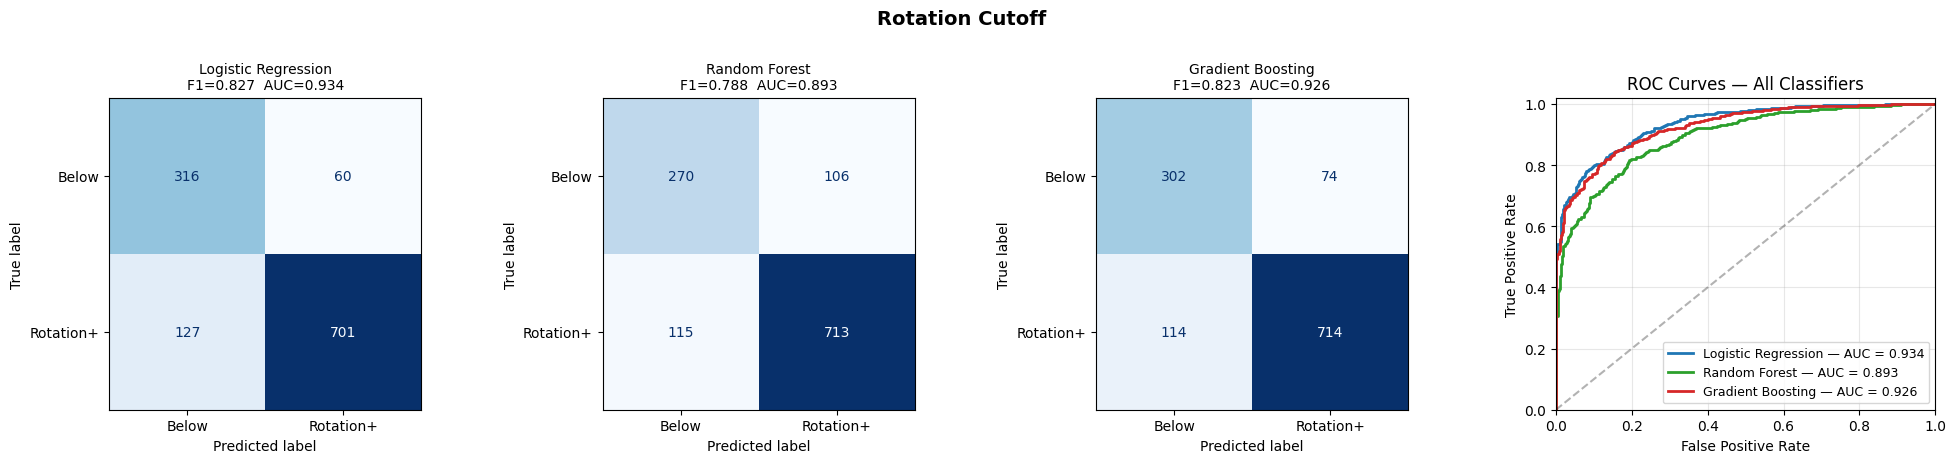

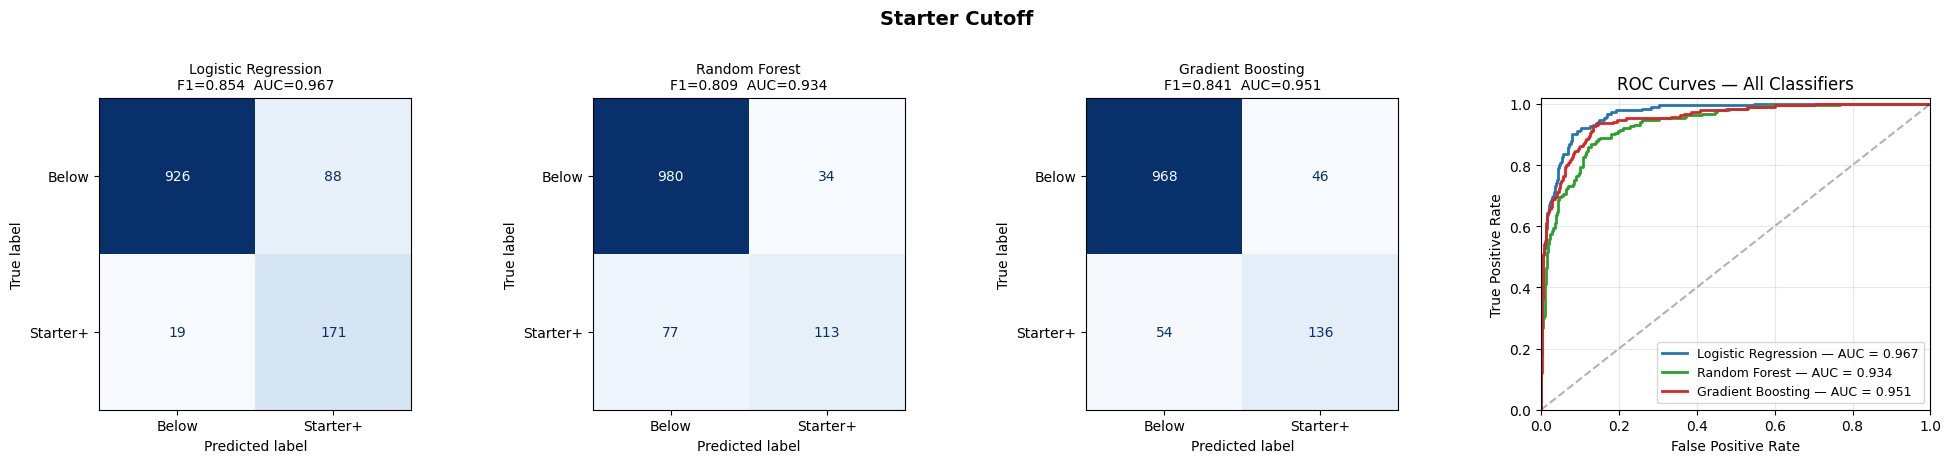

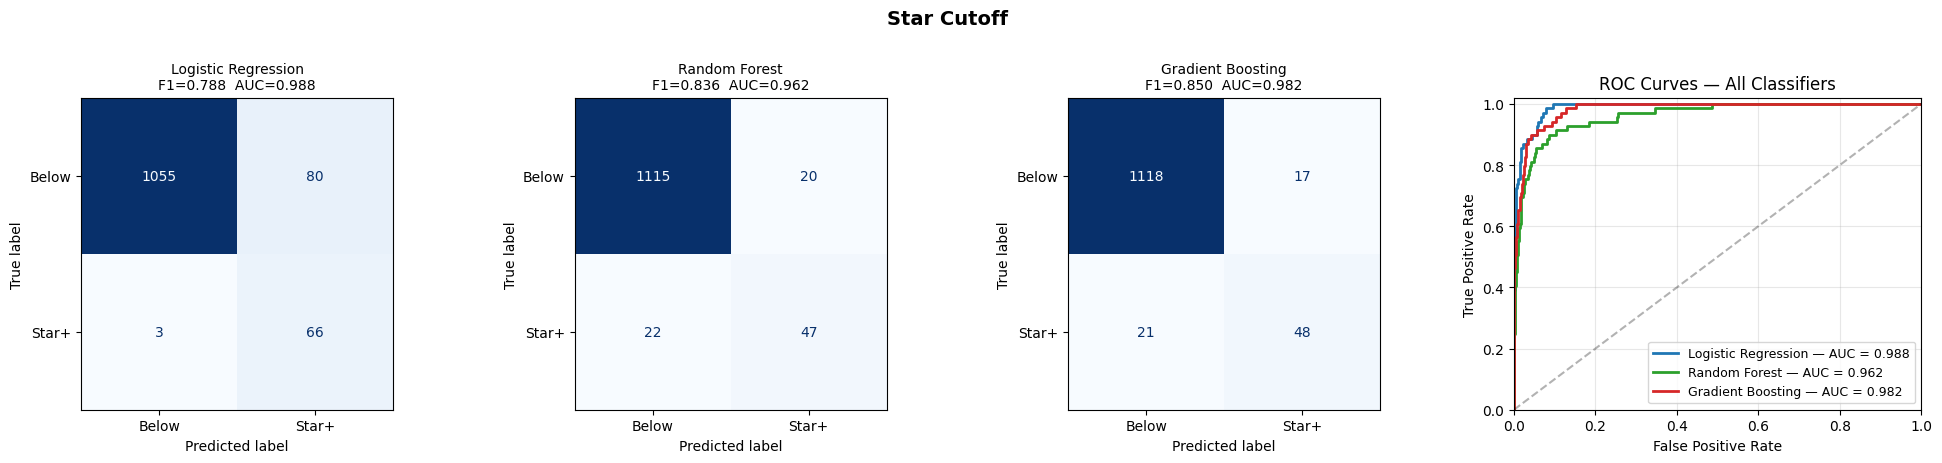

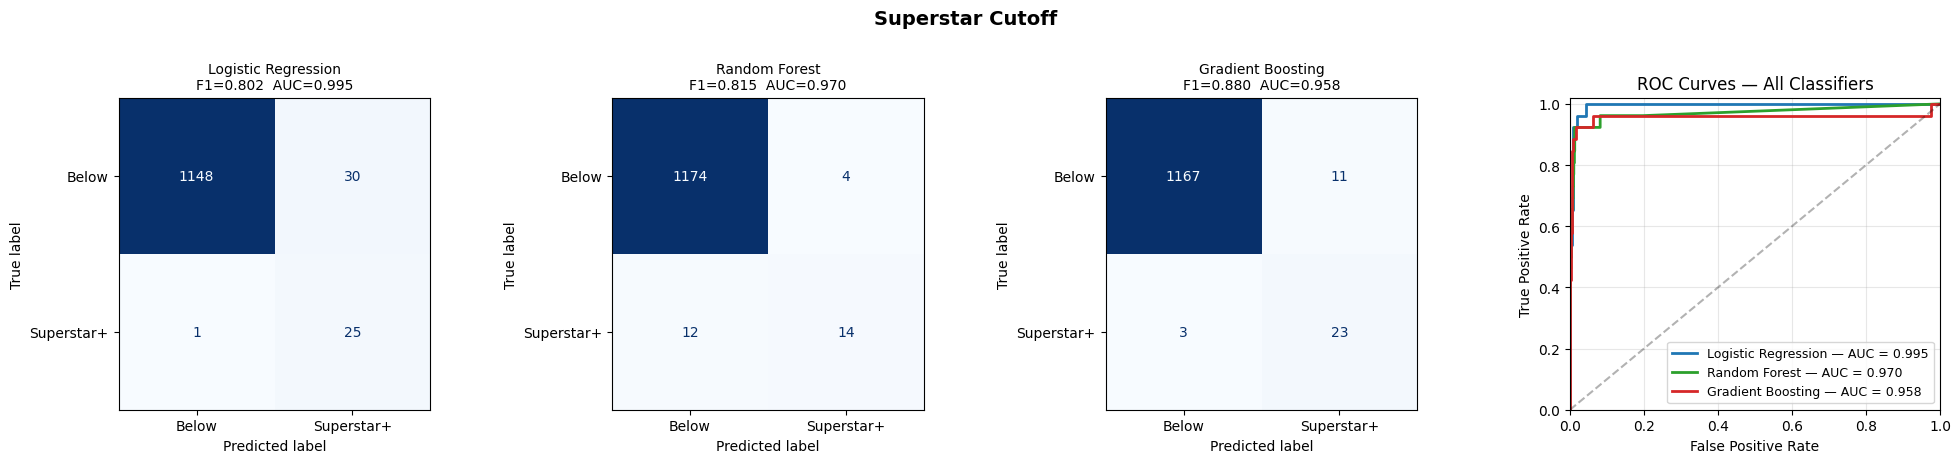

In [21]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cutoff_display = {
    'bpm_rotation':  ('Rotation',  'Rotation+'),
    'bpm_starter':   ('Starter',   'Starter+'),
    'bpm_star':      ('Star',      'Star+'),
    'bpm_superstar': ('Superstar', 'Superstar+'),
}
classifier_order = ['Logistic Regression', 'Random Forest', 'Gradient Boosting']
colors = ['#1f77b4', '#2ca02c', '#d62728']

for cutoff_key, (short_name, pos_label) in cutoff_display.items():
    # Get this cutoff's results and sort by fixed classifier order
    results = [r for r in all_results if r['cutoff'] == cutoff_key]
    results = sorted(results, key=lambda r: classifier_order.index(r['classifier']))

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

    # Confusion matrices in panels 0, 1, 2
    for i, r in enumerate(results):
        disp = ConfusionMatrixDisplay(
            confusion_matrix=r['confusion_matrix'],
            display_labels=['Below', pos_label],
        )
        disp.plot(ax=axes[i], cmap='Blues', colorbar=False)
        axes[i].set_title(
            f"{r['classifier']}\nF1={r['f1_macro']:.3f}  AUC={r['auc']:.3f}",
            fontsize=10,
        )

    # Overlay ROC plot in panel 3
    for r, color in zip(results, colors):
        fpr, tpr, _ = roc_curve(r['y_test'], r['y_proba'])
        axes[3].plot(fpr, tpr, color=color, linewidth=2,
                     label=f"{r['classifier']} — AUC = {r['auc']:.3f}")
    axes[3].plot([0, 1], [0, 1], 'k--', alpha=0.3)
    axes[3].set_xlabel('False Positive Rate')
    axes[3].set_ylabel('True Positive Rate')
    axes[3].set_title('ROC Curves — All Classifiers')
    axes[3].legend(loc='lower right', fontsize=9)
    axes[3].grid(alpha=0.3)
    axes[3].set_xlim([0, 1])
    axes[3].set_ylim([0, 1.02])

    plt.suptitle(f'{short_name} Cutoff', fontsize=14, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

### Interpreting the Figures:

Each of the four figures above presents the complete evaluation of all three classifiers on a single BPM cutoff. The three confusion matrices show classification performance at the default 0.5 probability threshold--true positives and true negatives on the diagonal, false positives and false negatives off-diagonal. The overlay ROC plot in the rightmost panel shows how each model's true-positive vs. false-positive rate trades off across all decision thresholds; curves closer to the top-left corner indicate better ranking quality.

A consistent pattern emerges across the four cutoffs: all three classifiers' ROC curves climb steeply from the origin, indicating that even at very low false-positive rates the models successfully identify a large fraction of true positives. Tree-based models (Random Forest, Gradient Boosting) tend to dominate at the stricter cutoffs (Star, Superstar), where capturing non-linear feature interactions matters more, while Logistic Regression remains competitive at the looser cutoffs (Rotation, Starter) where the decision boundary is approximately additive.

Computing the Summary Statistics:

From each model's confusion matrix and probability outputs, we compute four standard classification metrics that summarize what the visualizations show:

Accuracy: the fraction of all predictions that are correct:

$$ \text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} $$

Accuracy is intuitive but can be misleading on imbalanced datasets. At the Superstar cutoff (~2% positive class), a trivial model that always predicts "below" achieves 98% accuracy without learning anything meaningful.

Precision and Recall: per-class quality measures:

$$ \text{Precision} = \frac{TP}{TP + FP} \qquad \text{Recall} = \frac{TP}{TP + FN} $$

Precision answers "of the players I predicted as positive, how many actually were?" Recall answers "of the players who actually were positive, how many did I correctly identify?"

Macro F1: the harmonic mean of precision and recall, computed per class and then averaged equally across both classes:

$$ F1_c = \frac{2 \cdot \text{Precision}_c \cdot \text{Recall}_c}{\text{Precision}_c + \text{Recall}_c} \qquad \text{Macro F1} = \frac{F1_0 + F1_1}{2} $$

Averaging across classes equally (rather than weighting by class frequency) ensures the rare positive class contributes equally to the score — a model that ignores the minority class cannot achieve a high macro F1.

AUC (Area Under the ROC Curve): the model's ranking quality across all possible decision thresholds, computed as the integral of true-positive rate with respect to false-positive rate. AUC = 1.0 indicates perfect separation; AUC = 0.5 indicates random ranking. Unlike accuracy and F1, AUC does not depend on the chosen probability threshold — it measures whether the model assigns higher probabilities to true positives than to true negatives on average.

Using these results, we can now compute our final performance statistics:

In [22]:
summary = pd.DataFrame([
    {
        'Cutoff':     r['cutoff'],
        'Classifier': r['classifier'],
        'Accuracy':   round(r['accuracy'], 4),
        'Macro F1':   round(r['f1_macro'], 4),
        'AUC':        round(r['auc'], 4),
    }
    for r in all_results
]).sort_values(['Cutoff', 'Macro F1'], ascending=[True, False])

print("Final Summary — All 12 Classifier-Cutoff Combinations")
print("=" * 72)
print(summary.to_string(index=False))

Final Summary — All 12 Classifier-Cutoff Combinations
       Cutoff          Classifier  Accuracy  Macro F1    AUC
 bpm_rotation Logistic Regression    0.8447    0.8270 0.9342
 bpm_rotation   Gradient Boosting    0.8439    0.8231 0.9255
 bpm_rotation       Random Forest    0.8164    0.7877 0.8928
     bpm_star   Gradient Boosting    0.9684    0.8499 0.9822
     bpm_star       Random Forest    0.9651    0.8363 0.9615
     bpm_star Logistic Regression    0.9311    0.7881 0.9885
  bpm_starter Logistic Regression    0.9111    0.8535 0.9671
  bpm_starter   Gradient Boosting    0.9169    0.8410 0.9511
  bpm_starter       Random Forest    0.9078    0.8085 0.9343
bpm_superstar   Gradient Boosting    0.9884    0.8804 0.9576
bpm_superstar       Random Forest    0.9867    0.8148 0.9702
bpm_superstar Logistic Regression    0.9743    0.8020 0.9946


### Performance Summary: 

Across all twelve classifier-cutoff combinations, every model achieved macro F1 above 0.78 and AUC above 0.89 on the held-out test set. The best-performing classifier varies by cutoff: Logistic Regression wins the Rotation (F1=0.827) and Starter (F1=0.854) cutoffs, while Gradient Boosting wins the Star (F1=0.850) and Superstar (F1=0.880) cutoffs. Random Forest is consistently the third-best classifier at every cutoff but never the worst by a large margin.

Although raw accuracy climbs from 84% (Rotation) to 99% (Superstar), this is largely a function of increasing class imbalance: predicting "below threshold" for every player would achieve 98% accuracy at the Superstar cutoff. Macro F1 and AUC, which are robust to base-rate effects, show  a more nuance picture: macro F1 stays in a tight 0.79-0.88 band across all four cutoffs, indicating that classification performance is genuinely strong at every threshold, not inflated by majority-class predictions.

### Implications:

The classifier rankings shift systematically with cutoff difficulty, and the pattern is consistent enough to be analytically meaningful rather than
incidental. At the Rotation and Starter cutoffs, Logistic Regression and Gradient Boosting are nearly tied (within 0.01 macro F1), with Logistic
Regression actually winning both. At the Star and Superstar cutoffs, Gradient Boosting pulls ahead by a more meaningful margin (0.06 F1 at Star, 0.08 F1 at Superstar), and Random Forest also closes the gap on Logistic Regression. The most likely explanation lies in the geometry of each cutoff's decision boundary.

Logistic Regression learns a single linear hyperplane through the 34-dimensional feature space--one fixed combination of features that separates positive from negative cases. This works well when the underlying distinction is approximately additive: at the Rotation cutoff, the line between "below-replacement" and "rotation contributor" can be drawn cleanly in terms of volume (a player with more minutes, more points, more rebounds, and
more assists is more likely to be a rotation player, with each feature pulling roughly independently in the same direction). Most below-rotation players are clustered together at low values across most stats, and most rotation players are clustered together at higher values. A straight line through that space is a more optimal separator.

The geometry changes at the elite cutoffs. Distinguishing a star from a non-star--or a superstar from a non-superstar--is no longer a question of
pure production volume. There are many high-volume scorers who are not stars that contribute meaningfully to winning (because they shoot inefficiently, are net-negatives in many other area, or many other reasons), and there are stars who aren't towards the very top of the league in any single statistic (because their value comes from a balance of efficiency, playmaking, and defense, for example). The distinction becomes inherently interaction-driven: it is not "high points" that predicts star status, but "high points combined with high efficiency combined with positive non-scoring contribution." A 25-points-per-game player shooting 42% true-shooting with negative defense contributes far less  (and is not a true star); a 25-PPG player shooting 60% TS with positive defense almost certainly is. Logistic Regression, constrained to a single linear hyperplane, cannot represent this "high X AND high Y" relationship without manual feature engineering--it must assign one fixed weight to each feature regardless of the values of the others.

Gradient Boosting captures these interactions natively. Each decision tree in the boosting ensemble asks a sequence of questions ("Is FGA/game > 12? If yes, is eFG% > 0.55? If yes, is AST > 5?") that explicitly condition later splits on the outcomes of earlier ones. The model can learn that scoring volume only matters when paired with efficiency, that AST thresholds mean different things for different positions, and that a defensive counting stat like BLK is more predictive of impact for taller players than shorter ones. Random Forest learns the same kind of conditional logic but through independent trees rather than sequential ones, which is why it lands between Logistic Regression and Gradient Boosting in the rankings: it captures interactions but doesn't refine them through error-correction the way boosting does.

This pattern--linear models doing well on broad, additive distinctions and tree-based models doing better on narrow, interaction-driven distinctions--is a well-known phenomenon in machine learning. This finding reflects the shift in usage of analytics as quality of player increases; the structure of analysis shifts from measuring who produces raw statistics to measuring who combines this production with other aspects of the game in more effective ways. When distinguishing between players towards the top of the league, pure counting stats (points, rebounds, assists, etc.) are useful, but true analysis requires deeper thought. Once volume statistics are all largely high (most All-stars score at an above-average rate and play a meaningful amount of minutes), the question becomes about combinations of qualities. Does this player pair high scoring volume with efficient shooting? Does high assists come with low turnovers? Does scoring contribution coexist with defensive impact? These are inherently conditional questions--the predictive value of one statistic depends on the values of others--and no single linear weighting can encode them. All-NBA and MVP cases are argued on the basis of how a player's production interlocks across the entire spectrum of basketball. Gradient Boosting's tree structure captures this conditional reasoning, which is why it pulls ahead at the Star and Superstar cutoffs while remaining roughly equivalent at the lower ones.